# Aprendizado Supervisionado: Classificação e Regressão

Objetivo
- Treinar modelos de classificação e regressão
- Avaliar o desempenho utilizando métricas apropriadas
- Alterar modelos e parâmetros
- Interpretar resultados e gráficos

**IMPORTANTE**: Não basta executar o código.

Você deve modificar partes do código e responder às perguntas.

# Prática Guiada — Aprendizado Supervisionado com Scikit-learn

## Tema
Classificação, regressão, separação de dados, treinamento, avaliação e escolha de modelos.

## Objetivos
Ao final desta prática,  deverá ser capaz de:

- diferenciar problemas de classificação e regressão;
- separar os dados em treino e teste;
- treinar modelos com bibliotecas do Python;
- avaliar modelos com métricas adequadas;
- interpretar gráficos e resultados;
- comparar modelos e justificar a escolha do melhor.

## Instruções
- Execute todas as células.
- Leia as explicações antes de rodar o código.
- Realize as alterações solicitadas.
- Responda às perguntas em células de texto (para fixar conteúdo).
- Não apague os resultados gerados.

## Entrega
Responder Questionário no AVA.

In [ ]:
# ============================================================
# IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Modelos de classificação
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Modelos de regressão
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# Métricas de classificação
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Métricas de regressão
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

RANDOM_STATE = 42

# Parte 1 — Problema de Classificação

Nesta parte, vamos trabalhar com um problema de **classificação**.

## Contexto
Usaremos um conjunto de dados sobre diagnóstico de câncer de mama.

A variável alvo indica se o tumor é:

- maligno
- benigno

Logo, o objetivo do modelo é prever **uma classe**.

## O que será feito
1. Carregar os dados
2. Separar em treino e teste
3. Padronizar os atributos
4. Treinar dois modelos
5. Avaliar os resultados

# Parte 1 — Problema de Classificação

Nesta parte, vamos trabalhar com um problema de **classificação**.

## Contexto
Usaremos um conjunto de dados sobre diagnóstico de câncer de mama.

A variável alvo indica se o tumor é:

- maligno
- benigno

Logo, o objetivo do modelo é prever **uma classe**.

## O que será feito
1. Carregar os dados
2. Separar em treino e teste
3. Padronizar os atributos
4. Treinar dois modelos
5. Avaliar os resultados

In [ ]:
# ============================================================
# CARREGAMENTO DO DATASET DE CLASSIFICAÇÃO
# ============================================================

cancer = load_breast_cancer()

X_class = cancer.data
y_class = cancer.target

df_cancer = pd.DataFrame(X_class, columns=cancer.feature_names)
df_cancer["target"] = y_class

print("Primeiras 5 linhas do dataset:")
display(df_cancer.head())

print("Formato dos dados:", X_class.shape)
print("Classes:", cancer.target_names)
print("Distribuição da variável alvo:")
print(df_cancer["target"].value_counts())

Primeiras 5 linhas do dataset:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Formato dos dados: (569, 30)
Classes: ['malignant' 'benign']
Distribuição da variável alvo:
target
1    357
0    212
Name: count, dtype: int64


## Análise inicial da base de classificação

Responda:

1. Esse problema é de classificação ou regressão?
2. O que representa a variável alvo?
3. Quantas classes existem?
4. A base parece balanceada ou desbalanceada?

In [ ]:
# ============================================================
# SEPARAÇÃO EM TREINO E TESTE
# ============================================================

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_class,
    y_class,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_class
)

print("Quantidade de amostras de treino:", Xc_train.shape[0])
print("Quantidade de amostras de teste:", Xc_test.shape[0])

Quantidade de amostras de treino: 455
Quantidade de amostras de teste: 114


## Separação dos dados

A separação entre treino e teste é fundamental porque:

- o modelo aprende no conjunto de treino;
- o conjunto de teste simula dados novos;
- isso permite avaliar a capacidade de generalização.

Sem essa separação, poderíamos concluir erroneamente que o modelo é bom apenas porque decorou os dados.

In [ ]:
# ============================================================
# PADRONIZAÇÃO DOS DADOS
# ============================================================

scaler_class = StandardScaler()

Xc_train_scaled = scaler_class.fit_transform(Xc_train)
Xc_test_scaled = scaler_class.transform(Xc_test)

print("Padronização concluída.")

Padronização concluída.


## Padronização

A padronização coloca os atributos em uma escala comparável.

Isso é especialmente importante para modelos como:

- k-NN
- regressão logística
- SVM

pois eles são sensíveis à magnitude dos atributos.

In [ ]:
# ============================================================
# TREINAMENTO DOS MODELOS DE CLASSIFICAÇÃO
# ============================================================

modelo_log = LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)
modelo_knn = KNeighborsClassifier(n_neighbors=5)

modelo_log.fit(Xc_train_scaled, yc_train)
modelo_knn.fit(Xc_train_scaled, yc_train)

yc_train_pred_log = modelo_log.predict(Xc_train_scaled)
yc_test_pred_log = modelo_log.predict(Xc_test_scaled)

yc_train_pred_knn = modelo_knn.predict(Xc_train_scaled)
yc_test_pred_knn = modelo_knn.predict(Xc_test_scaled)

print("Modelos treinados com sucesso.")

Modelos treinados com sucesso.


In [ ]:
# ============================================================
# FUNÇÃO DE AVALIAÇÃO PARA CLASSIFICAÇÃO
# ============================================================

def avaliar_classificacao(nome_modelo, y_train, y_train_pred, y_test, y_test_pred, nomes_classes):
    print("=" * 60)
    print(f"MODELO: {nome_modelo}")
    print("=" * 60)

    acc_train = accuracy_score(y_train, y_train_pred)
    acc_test = accuracy_score(y_test, y_test_pred)
    prec = precision_score(y_test, y_test_pred)
    rec = recall_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred)

    print(f"Acurácia no treino: {acc_train:.4f}")
    print(f"Acurácia no teste : {acc_test:.4f}")
    print(f"Precisão          : {prec:.4f}")
    print(f"Recall            : {rec:.4f}")
    print(f"F1-score          : {f1:.4f}")

    print("\nRelatório de classificação:")
    print(classification_report(y_test, y_test_pred, target_names=nomes_classes))

    cm = confusion_matrix(y_test, y_test_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nomes_classes)
    disp.plot()
    plt.title(f"Matriz de Confusão - {nome_modelo}")
    plt.show()

MODELO: Regressão Logística
Acurácia no treino: 0.9890
Acurácia no teste : 0.9825
Precisão          : 0.9861
Recall            : 0.9861
F1-score          : 0.9861

Relatório de classificação:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



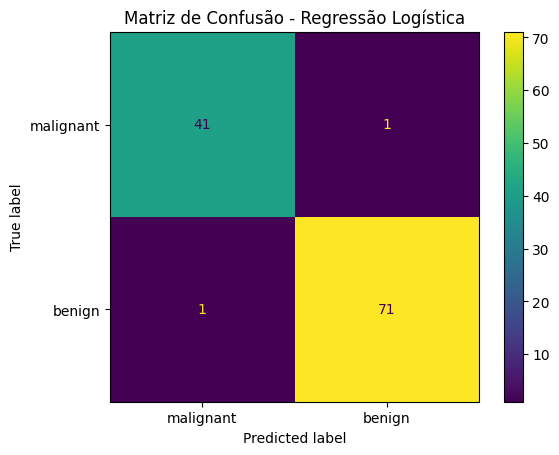

MODELO: k-NN (k=5)
Acurácia no treino: 0.9736
Acurácia no teste : 0.9561
Precisão          : 0.9589
Recall            : 0.9722
F1-score          : 0.9655

Relatório de classificação:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



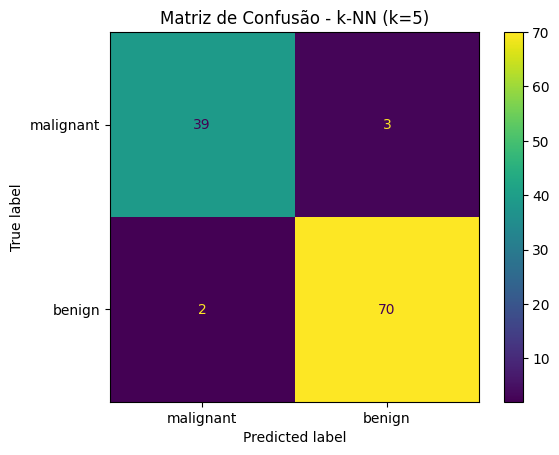

In [ ]:
# ============================================================
# AVALIAÇÃO DOS MODELOS
# ============================================================

avaliar_classificacao(
    "Regressão Logística",
    yc_train,
    yc_train_pred_log,
    yc_test,
    yc_test_pred_log,
    cancer.target_names
)

avaliar_classificacao(
    "k-NN (k=5)",
    yc_train,
    yc_train_pred_knn,
    yc_test,
    yc_test_pred_knn,
    cancer.target_names
)

##  — Comparação inicial dos modelos de classificação

Responda:

1. Qual modelo teve melhor acurácia no teste?
2. Houve grande diferença entre treino e teste?
3. Algum modelo parece ter sofrido overfitting?
4. Observando a matriz de confusão, o modelo cometeu muitos erros?

# Parte 2 — Atividade Guiada de Alteração de Modelo

Agora começa a parte prática orientada.

## Sua tarefa
Substituir o modelo k-NN por uma **Árvore de Decisão** e comparar os resultados.

## Objetivo
Perceber que diferentes algoritmos podem ter desempenhos diferentes no mesmo problema.

MODELO: Árvore de Decisão (max_depth=3)
Acurácia no treino: 0.9758
Acurácia no teste : 0.9386
Precisão          : 0.9452
Recall            : 0.9583
F1-score          : 0.9517

Relatório de classificação:
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



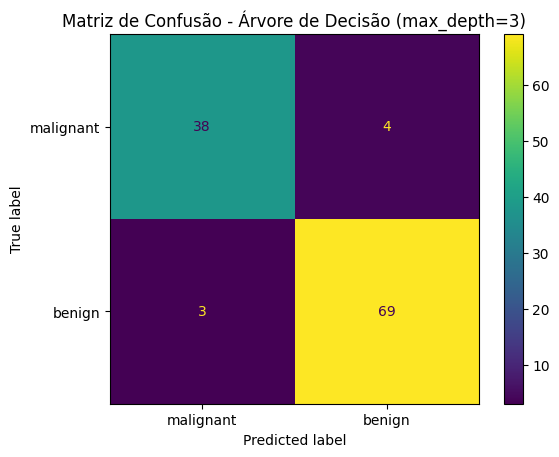

In [ ]:
# ============================================================
# ATIVIDADE 1 - SUBSTITUIR k-NN POR ÁRVORE DE DECISÃO
# ============================================================

modelo_tree_class = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
modelo_tree_class.fit(Xc_train_scaled, yc_train)

yc_train_pred_tree = modelo_tree_class.predict(Xc_train_scaled)
yc_test_pred_tree = modelo_tree_class.predict(Xc_test_scaled)

avaliar_classificacao(
    "Árvore de Decisão (max_depth=3)",
    yc_train,
    yc_train_pred_tree,
    yc_test,
    yc_test_pred_tree,
    cancer.target_names
)

## — Atividade 1

Responda:

1. O desempenho da árvore foi melhor ou pior que o k-NN?
2. A árvore apresentou diferença grande entre treino e teste?
3. Qual modelo você escolheria entre regressão logística, k-NN e árvore?
4. Justifique sua resposta usando métricas e gráfico.

# Parte 3 — Alteração de Parâmetros no k-NN

No algoritmo k-NN, o parâmetro `n_neighbors` define quantos vizinhos serão considerados.

## Sua tarefa
Testar diferentes valores de k e comparar os resultados.

### Testes sugeridos
- k = 1
- k = 5
- k = 10

In [ ]:
# ============================================================
# ATIVIDADE 2 - TESTAR DIFERENTES VALORES DE k
# ============================================================

valores_k = [1, 5, 10]

resultados_knn = []

for k in valores_k:
    modelo_knn_temp = KNeighborsClassifier(n_neighbors=k)
    modelo_knn_temp.fit(Xc_train_scaled, yc_train)

    pred_train = modelo_knn_temp.predict(Xc_train_scaled)
    pred_test = modelo_knn_temp.predict(Xc_test_scaled)

    acc_train = accuracy_score(yc_train, pred_train)
    acc_test = accuracy_score(yc_test, pred_test)

    resultados_knn.append({
        "k": k,
        "acuracia_treino": acc_train,
        "acuracia_teste": acc_test
    })

df_resultados_knn = pd.DataFrame(resultados_knn)
display(df_resultados_knn)

,k,acuracia_treino,acuracia_teste
0,1,1.000000,0.938596
1,5,0.973626,0.956140
2,10,0.975824,0.964912


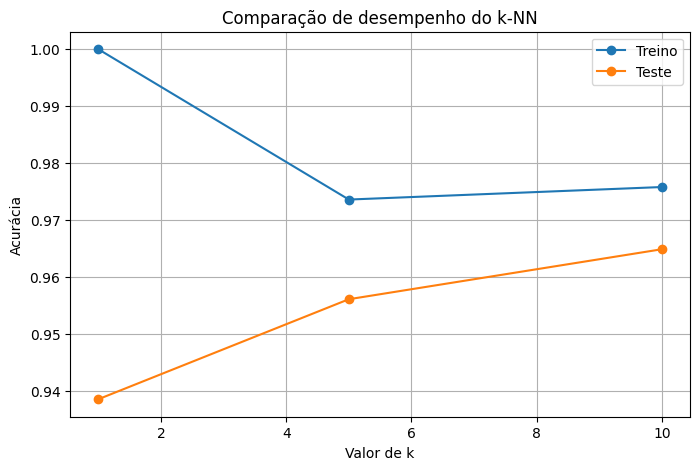

In [ ]:
# Gráfico comparativo para diferentes valores de k

plt.figure(figsize=(8,5))
plt.plot(df_resultados_knn["k"], df_resultados_knn["acuracia_treino"], marker='o', label="Treino")
plt.plot(df_resultados_knn["k"], df_resultados_knn["acuracia_teste"], marker='o', label="Teste")
plt.xlabel("Valor de k")
plt.ylabel("Acurácia")
plt.title("Comparação de desempenho do k-NN")
plt.legend()
plt.grid(True)
plt.show()

## — Atividade 2

Responda:

1. Qual valor de k teve melhor desempenho no teste?
2. Quando k = 1, o modelo parece mais sensível ou mais estável?
3. Um valor muito baixo de k pode favorecer overfitting? Explique.
4. Qual valor de k você escolheria?

# Parte 4 — Problema de Regressão

Agora vamos trabalhar com um problema de **regressão**.

## Contexto
Usaremos um conjunto de dados sobre diabetes.

A variável alvo é numérica e contínua.

Logo, o objetivo do modelo é prever **um valor numérico**.

In [ ]:
# ============================================================
# CARREGAMENTO DO DATASET DE REGRESSÃO
# ============================================================

diabetes = load_diabetes()

X_reg = diabetes.data
y_reg = diabetes.target

df_diabetes = pd.DataFrame(X_reg, columns=diabetes.feature_names)
df_diabetes["target"] = y_reg

print("Primeiras 5 linhas do dataset:")
display(df_diabetes.head())

print("Formato dos dados:", X_reg.shape)
print("Descrição estatística da variável alvo:")
display(df_diabetes["target"].describe())

Primeiras 5 linhas do dataset:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


Formato dos dados: (442, 10)
Descrição estatística da variável alvo:


,target
count,442.000000
mean,152.133484
std,77.093005
min,25.000000
25%,87.000000
50%,140.500000
75%,211.500000
max,346.000000


## — Análise inicial da base de regressão

Responda:

1. Esse problema é de classificação ou regressão?
2. Como você percebe isso observando a variável alvo?
3. Que tipo de saída o modelo deverá prever?

In [ ]:
# ============================================================
# SEPARAÇÃO TREINO E TESTE - REGRESSÃO
# ============================================================

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("Quantidade de amostras de treino:", Xr_train.shape[0])
print("Quantidade de amostras de teste:", Xr_test.shape[0])

Quantidade de amostras de treino: 353
Quantidade de amostras de teste: 89


In [ ]:
# ============================================================
# PADRONIZAÇÃO PARA REGRESSÃO LINEAR
# ============================================================

scaler_reg = StandardScaler()

Xr_train_scaled = scaler_reg.fit_transform(Xr_train)
Xr_test_scaled = scaler_reg.transform(Xr_test)

print("Padronização concluída.")

Padronização concluída.


In [ ]:
# ============================================================
# TREINAMENTO DOS MODELOS DE REGRESSÃO
# ============================================================

modelo_lr = LinearRegression()
modelo_tree_reg = DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE)

modelo_lr.fit(Xr_train_scaled, yr_train)
modelo_tree_reg.fit(Xr_train, yr_train)

yr_train_pred_lr = modelo_lr.predict(Xr_train_scaled)
yr_test_pred_lr = modelo_lr.predict(Xr_test_scaled)

yr_train_pred_tree = modelo_tree_reg.predict(Xr_train)
yr_test_pred_tree = modelo_tree_reg.predict(Xr_test)

print("Modelos de regressão treinados com sucesso.")

Modelos de regressão treinados com sucesso.


In [ ]:
# ============================================================
# FUNÇÃO DE AVALIAÇÃO PARA REGRESSÃO
# ============================================================

def avaliar_regressao(nome_modelo, y_train, y_train_pred, y_test, y_test_pred):
    print("=" * 60)
    print(f"MODELO: {nome_modelo}")
    print("=" * 60)

    mae_train = mean_absolute_error(y_train, y_train_pred)
    mse_train = mean_squared_error(y_train, y_train_pred)
    rmse_train = np.sqrt(mse_train)
    r2_train = r2_score(y_train, y_train_pred)

    mae_test = mean_absolute_error(y_test, y_test_pred)
    mse_test = mean_squared_error(y_test, y_test_pred)
    rmse_test = np.sqrt(mse_test)
    r2_test = r2_score(y_test, y_test_pred)

    print("Treino:")
    print(f"MAE  : {mae_train:.4f}")
    print(f"MSE  : {mse_train:.4f}")
    print(f"RMSE : {rmse_train:.4f}")
    print(f"R²   : {r2_train:.4f}")

    print("\nTeste:")
    print(f"MAE  : {mae_test:.4f}")
    print(f"MSE  : {mse_test:.4f}")
    print(f"RMSE : {rmse_test:.4f}")
    print(f"R²   : {r2_test:.4f}")

    plt.figure(figsize=(7,5))
    plt.scatter(y_test, y_test_pred)
    plt.xlabel("Valor real")
    plt.ylabel("Valor predito")
    plt.title(f"Real x Predito - {nome_modelo}")
    plt.grid(True)
    plt.show()

MODELO: Regressão Linear
Treino:
MAE  : 43.4835
MSE  : 2868.5497
RMSE : 53.5588
R²   : 0.5279

Teste:
MAE  : 42.7941
MSE  : 2900.1936
RMSE : 53.8534
R²   : 0.4526


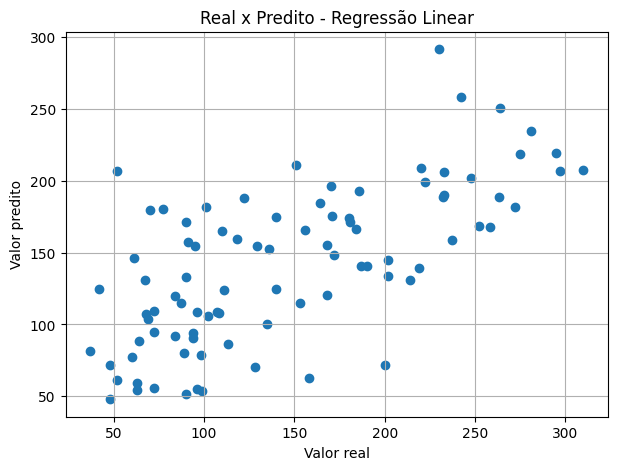

MODELO: Árvore de Regressão (max_depth=4)
Treino:
MAE  : 40.0738
MSE  : 2524.2545
RMSE : 50.2420
R²   : 0.5846

Teste:
MAE  : 47.0454
MSE  : 3568.9653
RMSE : 59.7408
R²   : 0.3264


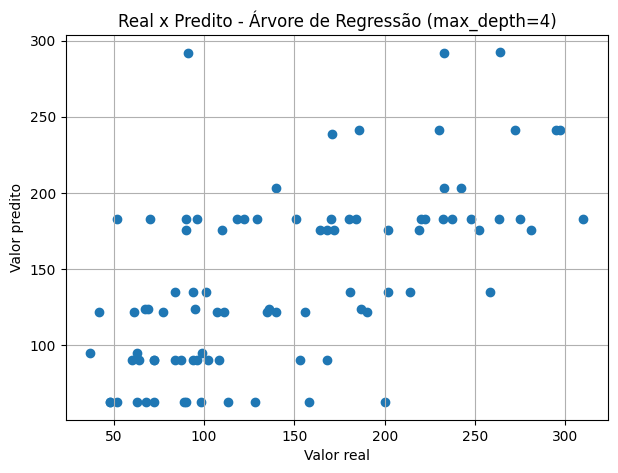

In [ ]:
# ============================================================
# AVALIAÇÃO DOS MODELOS DE REGRESSÃO
# ============================================================

avaliar_regressao(
    "Regressão Linear",
    yr_train,
    yr_train_pred_lr,
    yr_test,
    yr_test_pred_lr
)

avaliar_regressao(
    "Árvore de Regressão (max_depth=4)",
    yr_train,
    yr_train_pred_tree,
    yr_test,
    yr_test_pred_tree
)

## — Comparação inicial dos modelos de regressão

Responda:

1. Qual modelo apresentou menor RMSE no teste?
2. Qual modelo teve melhor R² no teste?
3. O gráfico real x predito parece mais concentrado em qual modelo?
4. Houve indício de overfitting em algum deles?

# Parte 5 — Atividade Guiada de Alteração de Parâmetros na Regressão

Agora você vai testar diferentes profundidades na árvore de regressão.

## Sua tarefa
Comparar:
- max_depth = 2
- max_depth = 4
- max_depth = 10

## Objetivo
Verificar como a complexidade do modelo afeta o desempenho.

In [ ]:
# ============================================================
# ATIVIDADE 3 - TESTAR DIFERENTES PROFUNDIDADES
# ============================================================

profundidades = [2, 4, 10]
resultados_tree_reg = []

for profundidade in profundidades:
    modelo_temp = DecisionTreeRegressor(max_depth=profundidade, random_state=RANDOM_STATE)
    modelo_temp.fit(Xr_train, yr_train)

    pred_train = modelo_temp.predict(Xr_train)
    pred_test = modelo_temp.predict(Xr_test)

    rmse_train = np.sqrt(mean_squared_error(yr_train, pred_train))
    rmse_test = np.sqrt(mean_squared_error(yr_test, pred_test))
    r2_train = r2_score(yr_train, pred_train)
    r2_test = r2_score(yr_test, pred_test)

    resultados_tree_reg.append({
        "max_depth": profundidade,
        "rmse_treino": rmse_train,
        "rmse_teste": rmse_test,
        "r2_treino": r2_train,
        "r2_teste": r2_test
    })

df_tree_reg = pd.DataFrame(resultados_tree_reg)
display(df_tree_reg)

,max_depth,rmse_treino,rmse_teste,r2_treino,r2_teste
0,2,57.953649,61.118734,0.447267,0.294943
1,4,50.241960,59.740817,0.584580,0.326375
2,10,19.380510,66.241839,0.938186,0.171790


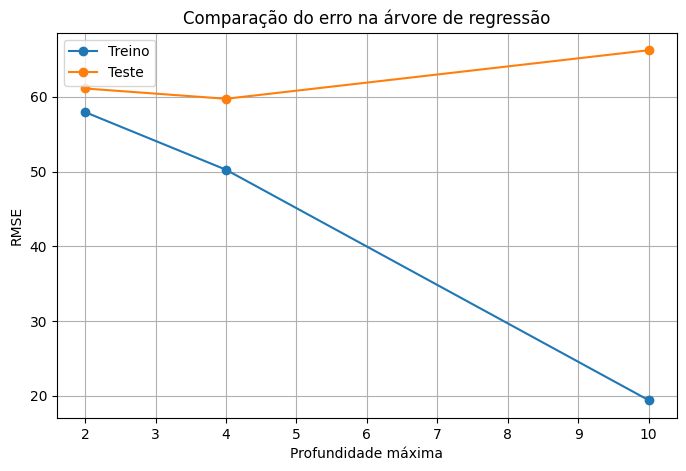

In [ ]:
# Gráfico de comparação de RMSE

plt.figure(figsize=(8,5))
plt.plot(df_tree_reg["max_depth"], df_tree_reg["rmse_treino"], marker='o', label="Treino")
plt.plot(df_tree_reg["max_depth"], df_tree_reg["rmse_teste"], marker='o', label="Teste")
plt.xlabel("Profundidade máxima")
plt.ylabel("RMSE")
plt.title("Comparação do erro na árvore de regressão")
plt.legend()
plt.grid(True)
plt.show()

## — Atividade 3

Responda:

1. Aumentar a profundidade sempre melhorou o desempenho no teste?
2. Em qual profundidade houve melhor equilíbrio entre treino e teste?
3. Qual profundidade parece indicar overfitting?
4. Por que comparar treino e teste é importante?

# Parte 6 — Comparação Final dos Modelos

Agora vamos organizar os resultados para facilitar a comparação final.

In [ ]:
# ============================================================
# RESUMO DOS RESULTADOS
# ============================================================

resumo_classificacao = pd.DataFrame({
    "modelo": ["Regressão Logística", "k-NN (k=5)", "Árvore de Decisão"],
    "acuracia_teste": [
        accuracy_score(yc_test, yc_test_pred_log),
        accuracy_score(yc_test, yc_test_pred_knn),
        accuracy_score(yc_test, yc_test_pred_tree)
    ],
    "f1_teste": [
        f1_score(yc_test, yc_test_pred_log),
        f1_score(yc_test, yc_test_pred_knn),
        f1_score(yc_test, yc_test_pred_tree)
    ]
})

resumo_regressao = pd.DataFrame({
    "modelo": ["Regressão Linear", "Árvore de Regressão (max_depth=4)"],
    "rmse_teste": [
        np.sqrt(mean_squared_error(yr_test, yr_test_pred_lr)),
        np.sqrt(mean_squared_error(yr_test, yr_test_pred_tree))
    ],
    "r2_teste": [
        r2_score(yr_test, yr_test_pred_lr),
        r2_score(yr_test, yr_test_pred_tree)
    ]
})

print("Resumo - Classificação")
display(resumo_classificacao)

print("Resumo - Regressão")
display(resumo_regressao)

Resumo - Classificação


,modelo,acuracia_teste,f1_teste
0,Regressão Logística,0.982456,0.986111
1,k-NN (k=5),0.956140,0.965517
2,Árvore de Decisão,0.938596,0.951724


Resumo - Regressão


,modelo,rmse_teste,r2_teste
0,Regressão Linear,53.853446,0.452603
1,Árvore de Regressão (max_depth=4),59.740817,0.326375


## — Conclusão final

Responda:

1. Qual a principal diferença entre classificação e regressão?
2. Em classificação, quais métricas foram mais úteis?
3. Em regressão, por que RMSE e R² são importantes?
4. Qual modelo você escolheria para a tarefa de classificação?
5. Qual modelo você escolheria para a tarefa de regressão?
6. O que você aprendeu com esta prática?

# Desafio opcional

Se puder, faça uma das extensões abaixo:

## Opção A
Substitua o modelo de classificação por outro algoritmo da biblioteca.

## Opção B
Teste novos valores de `n_neighbors` no k-NN.

## Opção C
Teste novas profundidades na árvore de regressão.

## Opção D
Explique, com suas palavras, a diferença entre:
- underfitting
- overfitting
- boa generalização